# Proyecto de Ciencia de Datos: exoplanetas de la misión Kepler
## Notebook 5 · Visualizaciones y narrativa de datos

**Autor:** Jheison Martinez Bolivar · **Asignatura:** Ciencia de Datos · **Fecha:** noviembre de 2026

Este cuaderno abre la **Fase 4** del proyecto (Actividad 7): convertir los resultados de los
cuadernos anteriores en **figuras que se pueden explicar en una sustentación**. La narrativa que
se propone aquí es la del informe final: qué distingue a un planeta de un falso positivo, cuánto
aportó cada decisión del proyecto, y el cierre natural: **clasificar los 1 977 candidatos** que
quedaban sin resolver.

1. Cargar modelo final (NB4), datos y resultados
2. La figura que cuenta la historia: periodo–radio y multiplicidad
3. Cuánto aportó cada fase: baseline → modelos avanzados
4. El cierre: los candidatos clasificados con su probabilidad
5. Tablero de resumen para la sustentación

## 1. Entorno, datos y modelo final

Se carga el **modelo ganador del Notebook 4** (reentrenado con train + validación) y las métricas
guardadas. Los candidatos no tienen `kepoi_name` en el parquet (el Notebook 2 los descartó como
identificadores), así que se recuperan del CSV crudo: los candidatos son *exactamente* las filas
con `koi_disposition = CANDIDATE`, en el mismo orden, y se lo comprueba con un `assert`.

In [1]:
# %pip install "pandas>=2.1" numpy matplotlib seaborn scikit-learn joblib pyarrow
import json
import warnings
from datetime import datetime, timezone
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from IPython.display import Markdown, display

warnings.filterwarnings("ignore", category=FutureWarning)

# --- Rutas, semilla y paleta (idénticos a NB1–NB4) ---------------------
DATA_DIR = Path("data")
RANDOM_STATE = 42
CONF, CAND, FP = "CONFIRMED", "CANDIDATE", "FALSE POSITIVE"
COLORES = {CONF: "#2a78d6", FP: "#eb6834", CAND: "#1baf7a"}
GRIS = "#8a8984"

sns.set_theme(style="whitegrid")
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.titleweight": "bold",
                     "grid.alpha": 0.35})
pd.set_option("display.max_columns", 40)

def md(texto: str) -> None:
    display(Markdown(texto))

def pct(x: float) -> str:
    return f"{100 * x:.1f} %"

print("Entorno listo.")

Entorno listo.


In [2]:
df = pd.read_parquet(DATA_DIR / "koi_clean.parquet")
y = df["es_planeta"].astype(int)
X = df.drop(columns="es_planeta")

cand = pd.read_parquet(DATA_DIR / "koi_candidatos.parquet").drop(columns="es_planeta")
modelo_final = joblib.load(DATA_DIR / "koi_modelo_final.joblib")
base = json.loads((DATA_DIR / "koi_metricas_baseline.json").read_text())
avanz = json.loads((DATA_DIR / "koi_metricas_modelos.json").read_text())

assert list(cand.columns) == list(X.columns), "NB2 y NB4 deben hablar de las mismas features"

# --- Nombres y valores crudos de los candidatos, desde el CSV ----------
raw = pd.read_csv(DATA_DIR / "koi_cumulative_raw.csv", low_memory=False,
                  dtype={"koi_quarters": str, "kepoi_name": str, "kepler_name": str})
mask_cand = raw["koi_disposition"] == CAND
assert int(mask_cand.sum()) == len(cand), "El conteo de candidatos no coincide con el CSV crudo"
crudos_cand = raw.loc[mask_cand, ["kepoi_name", "koi_period", "koi_prad", "koi_depth"]].reset_index(drop=True)

# Emparejamiento posicional fila a fila: el parquet se construyó desde este CSV en el
# mismo orden; se verifica via la equivalencia log1p <-> expm1 del periodo orbital.
per_cand = np.expm1(cand["log_koi_period"].values)
assert np.allclose(per_cand, crudos_cand["koi_period"].values, rtol=1e-6), \
    "El orden de los candidatos debe corresponder fila a fila con el CSV crudo"

# --- Predicción de los candidatos -------------------------------------
prob_cand = modelo_final.predict_proba(cand)[:, 1]
pred_cand = (prob_cand >= 0.5).astype(int)          # mismo umbral del modelo
clasif = pd.DataFrame({
    "kepoi_name": crudos_cand["kepoi_name"],
    "koi_period": crudos_cand["koi_period"],
    "koi_prad": crudos_cand["koi_prad"],
    "koi_depth": crudos_cand["koi_depth"],
    "prob_planeta": prob_cand,
    "pred_planeta": pred_cand,
})

CLASIF_PATH = DATA_DIR / "koi_candidatos_clasificados.parquet"
clasif.to_parquet(CLASIF_PATH, index=False)

n_planet = int(pred_cand.sum())
print(f"Modelo: {avanz['ganador']} (F1 macro prueba = {avanz['ganador_prueba']['F1 macro']:.3f})")
print(f"Candidatos: {len(cand):,} → {n_planet:,} clasificados como planeta ({pct(n_planet / len(cand))})")
print(f"Guardado: {CLASIF_PATH}")

Modelo: Gradient boosting (F1 macro prueba = 0.983)
Candidatos: 1,977 → 653 clasificados como planeta (33.0 %)
Guardado: data/koi_candidatos_clasificados.parquet


## 2. La figura que cuenta la historia

El EDA y los modelos convergen en dos ideas que **una sola figura** puede contar: el diagrama
periodo–radio es el mapa de los exoplanetas (los falsos positivos se amontonan en la esquina de
radio grande), y la **multiplicidad** es el rasgo que más separa (varias señales en una estrella
casi siempre son planetas reales). Aquí se recuentan ambas, pero con el resultado del modelo: los
candidatos que el modelo clasifica como planeta se dibujan como una tercera población.

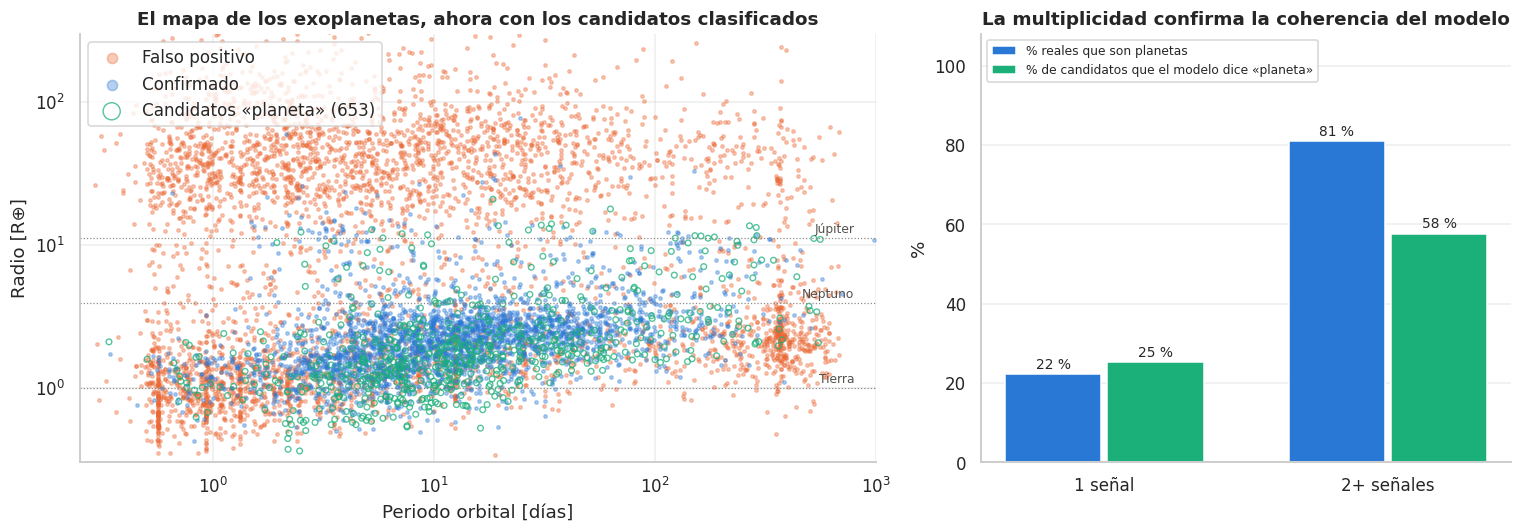

**Lectura.** De los 1,977 candidatos, el modelo propone **653 como planetas**. En el mapa, esa población (círculos verdes) se apila en la **región de los planetas reales** — radios menores, periodos intermedios — y no en la esquina de radio grande donde viven los eclipses binarios. Y en la coherencia de la multiplicidad: donde en realidad hay 81 % de planetas, el modelo vota «planeta» para el 58 % de los candidatos múltiples; donde hay solo 22 %, vota para el 25 %. **El modelo aprendió la física sin que se la explicáramos.**

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5), gridspec_kw={"width_ratios": [1.5, 1]})

# --- Izquierda: diagrama periodo-radio --------------------------------
ax = axes[0]
for clase, etiqueta in [(FP, "Falso positivo"), (CONF, "Confirmado")]:
    sub = raw.loc[raw["koi_disposition"] == clase]
    sub = sub[(sub["koi_prad"] > 0) & (sub["koi_period"] > 0)]
    ax.scatter(sub["koi_period"], sub["koi_prad"], s=5, alpha=0.35,
               color=COLORES[clase], label=etiqueta, rasterized=True)
sub_c = clasif.loc[clasif["pred_planeta"] == 1]
sub_c = sub_c[(sub_c["koi_prad"] > 0) & (sub_c["koi_period"] > 0)]
ax.scatter(sub_c["koi_period"], sub_c["koi_prad"], s=14, alpha=0.75, facecolors="none",
           edgecolors=COLORES[CAND], linewidths=0.9,
           label=f"Candidatos «planeta» ({len(sub_c):,})")
for r, nombre in [(1, "Tierra"), (3.9, "Neptuno"), (11.2, "Júpiter")]:
    ax.axhline(r, color=GRIS, lw=0.8, ls=":")
    ax.text(800, r * 1.09, nombre, color="#52514e", fontsize=8, ha="right")
ax.set(xscale="log", yscale="log", xlim=(0.25, 1000), ylim=(0.3, 300),
       xlabel="Periodo orbital [días]", ylabel="Radio [R⊕]",
       title="El mapa de los exoplanetas, ahora con los candidatos clasificados")
ax.legend(markerscale=3, frameon=True, loc="upper left")

# --- Derecha: multiplicidad -------------------------------------------
ax = axes[1]
cnt = df[["sistema_multiple", "es_planeta"]].copy()
cnt["n_senales"] = np.where(cnt["sistema_multiple"] == 1, "2+ señales", "1 señal")
tasa_real = cnt.groupby("n_senales")["es_planeta"].mean() * 100

cand_mult = cand["sistema_multiple"].values
tasa_pred = pd.Series(pred_cand).groupby(
    pd.Series(np.where(cand_mult == 1, "2+ señales", "1 señal"))).mean() * 100

x = np.arange(2)
ax.bar(x - 0.18, tasa_real.loc[["1 señal", "2+ señales"]], width=0.34,
       color=COLORES[CONF], label="% reales que son planetas")
ax.bar(x + 0.18, tasa_pred.reindex(["1 señal", "2+ señales"]), width=0.34,
       color=COLORES[CAND], label="% de candidatos que el modelo dice «planeta»")
for xi, v in zip(x - 0.18, tasa_real.loc[["1 señal", "2+ señales"]]):
    ax.text(xi, v + 1.5, f"{v:.0f} %", ha="center", fontsize=9)
for xi, v in zip(x + 0.18, tasa_pred.reindex(["1 señal", "2+ señales"])):
    ax.text(xi, v + 1.5, f"{v:.0f} %", ha="center", fontsize=9)
ax.set_xticks(x, ["1 señal", "2+ señales"])
ax.set_ylabel("%")
ax.set_ylim(0, 108)
ax.set_title("La multiplicidad confirma la coherencia del modelo")
ax.legend(frameon=True, fontsize=8, loc="upper left")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** De los {len(cand):,} candidatos, el modelo propone **{n_planet:,} como planetas**. En el mapa, \
esa población (círculos verdes) se apila en la **región de los planetas reales** — radios menores, \
periodos intermedios — y no en la esquina de radio grande donde viven los eclipses binarios. Y en \
la coherencia de la multiplicidad: donde en realidad hay {tasa_real.loc['2+ señales']:.0f} % de planetas, el modelo \
vota «planeta» para el {tasa_pred.loc['2+ señales']:.0f} % de los candidatos múltiples; donde hay solo {tasa_real.loc['1 señal']:.0f} %, \
vota para el {tasa_pred.loc['1 señal']:.0f} %. **El modelo aprendió la física sin que se la explicáramos.**""")

## 3. Cuánto aportó cada fase del proyecto

La comparación que la sustentación necesita en una sola vista: las dos referencias triviales, el
modelo lineal de referencia (NB3) y el ganador (NB4), medidos en **la misma prueba** (20 % de los
datos, tocada una sola vez).

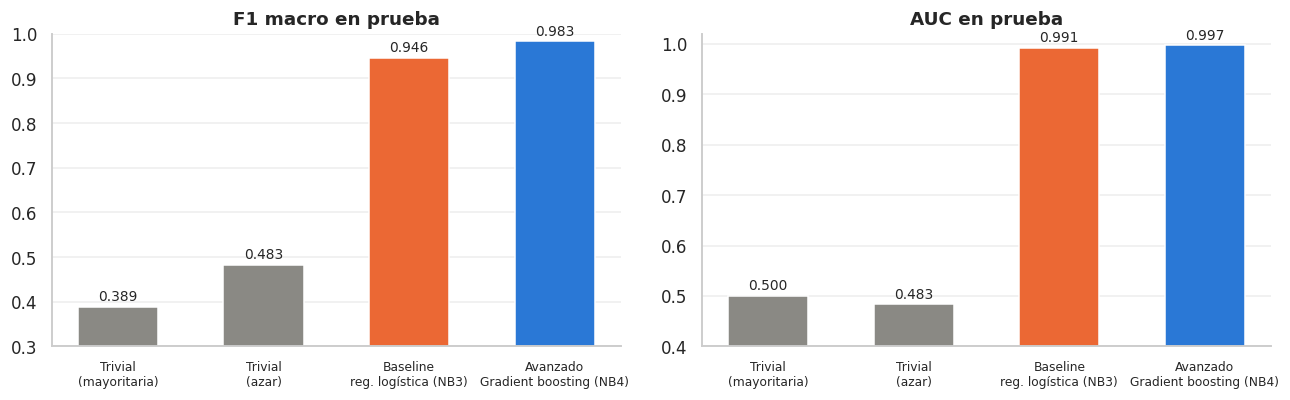

**Lectura.** El camino del proyecto en una imagen: las referencias triviales (gris) fijan el suelo (0.39 de F1 macro), la regresión logística del Notebook 3 lo sube hasta 0.946 demostrando que hay señal aprendible, y el Gradient boosting del Notebook 4 lo lleva a **0.983** (+0.036). Cada salto corresponde a una decisión documentada: sin fuga de datos, partición fija y comparación justa.

In [4]:
nombres = ["Trivial\n(mayoritaria)", "Trivial\n(azar)", "Baseline\nreg. logística (NB3)",
           "Avanzado\n" + avanz["ganador"] + " (NB4)"]
f1s = [base["prueba_trivial"]["clase_mayoritaria"]["F1 macro"],
       base["prueba_trivial"]["azar_estratificado"]["F1 macro"],
       base["prueba"]["F1 macro"],
       avanz["ganador_prueba"]["F1 macro"]]
aucs = [base["prueba_trivial"]["clase_mayoritaria"]["AUC"],
        base["prueba_trivial"]["azar_estratificado"]["AUC"],
        base["prueba"]["AUC"],
        avanz["ganador_prueba"]["AUC"]]

fig, axes = plt.subplots(1, 2, figsize=(12, 3.8))
colores = [GRIS, GRIS, COLORES[FP], COLORES[CONF]]
for ax, vals, titulo, lim in [(axes[0], f1s, "F1 macro en prueba", (0.3, 1.0)),
                              (axes[1], aucs, "AUC en prueba", (0.4, 1.02))]:
    barras = ax.bar(nombres, vals, color=colores, width=0.55)
    for b, v in zip(barras, vals):
        ax.text(b.get_x() + b.get_width() / 2, v + (lim[1] - lim[0]) * 0.02, f"{v:.3f}",
                ha="center", fontsize=9)
    ax.set_ylim(*lim)
    ax.set_title(titulo)
    ax.tick_params(axis="x", labelsize=8)
    ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

delta = avanz["ganador_prueba"]["F1 macro"] - base["prueba"]["F1 macro"]
md(f"""**Lectura.** El camino del proyecto en una imagen: las referencias triviales (gris) fijan el suelo \
({f1s[0]:.2f} de F1 macro), la regresión logística del Notebook 3 lo sube hasta {f1s[2]:.3f} demostrando que hay \
señal aprendible, y el {avanz['ganador']} del Notebook 4 lo lleva a **{f1s[3]:.3f}** (+{delta:.3f}). \
Cada salto corresponde a una decisión documentada: sin fuga de datos, partición fija y \
comparación justa.""")


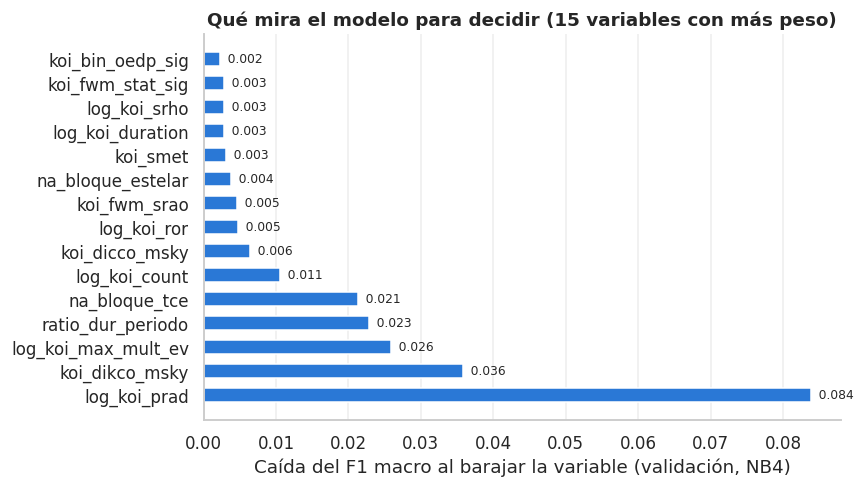

**Lectura.** El modelo mira lo mismo que mira un astrónomo: **la calidad de la señal** (log_koi_prad, koi_dikco_msky) y los **diagnósticos de vetting** que el Notebook 2 convirtió en indicadores. Nada de esto se explica sin la fase de limpieza: barajar cualquier de estas variables cuesta hasta 0.084 de F1 macro.

In [5]:
perm = pd.Series(avanz["permutacion_top15"]).sort_values()

fig, ax = plt.subplots(figsize=(8, 4.6))
ax.barh(perm.index[::-1], perm.values[::-1], color=COLORES[CONF], height=0.6)
for y_, v in enumerate(perm.values[::-1]):
    ax.text(v, y_, f"  {v:.3f}", va="center", fontsize=8)
ax.set_xlabel("Caída del F1 macro al barajar la variable (validación, NB4)")
ax.set_title("Qué mira el modelo para decidir (15 variables con más peso)")
ax.grid(axis="y", visible=False)
plt.tight_layout()
plt.show()

md(f"""**Lectura.** El modelo mira lo mismo que mira un astrónomo: **la calidad de la señal** ({perm.index[-1]}, \
{perm.index[-2]}) y los **diagnósticos de vetting** que el Notebook 2 convirtió en indicadores. Nada de \
esto se explica sin la fase de limpieza: barajar cualquier de estas variables cuesta hasta \
{perm.values[-1]:.3f} de F1 macro.""")


## 4. El cierre: clasificar los candidatos

Los 1 977 KOI que quedaban sin resolver son el argumento final del proyecto: un modelo entrenado
con señales ya verificadas que produce una **lista priorizada de candidatos a planeta**, con su
probabilidad. La lista completa queda en `data/koi_candidatos_clasificados.parquet`.

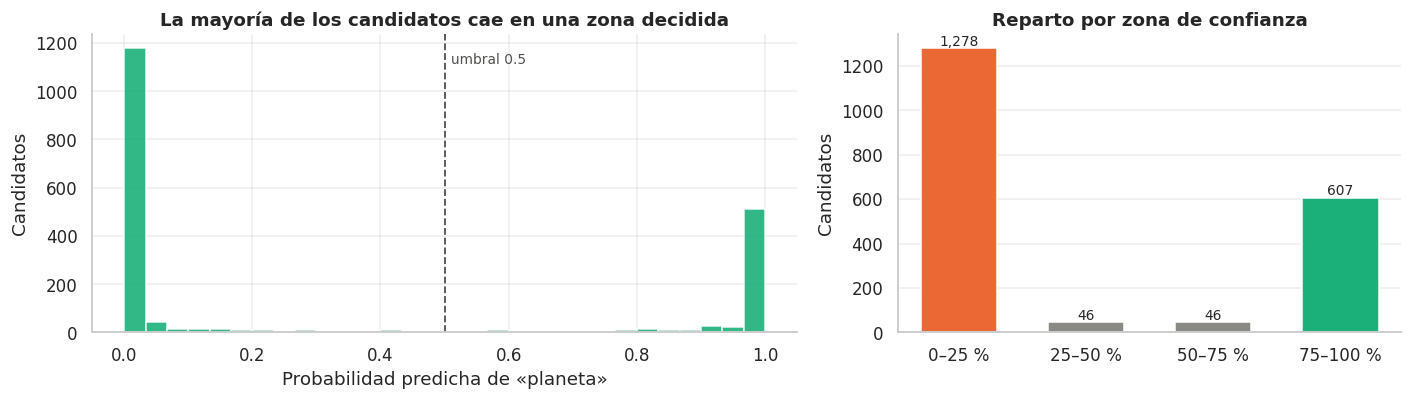

**Lectura.** El modelo es decidido: **607 candidatos con probabilidad ≥ 75 %** y 1,278 con menos del 25 %; solo 92 quedan en la zona gris. Para el equipo de seguimiento de Kepler eso se traduce en una lista priorizada: empezar por los de probabilidad alta.

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(13, 3.8), gridspec_kw={"width_ratios": [1.4, 1]})

ax = axes[0]
ax.hist(prob_cand, bins=np.linspace(0, 1, 31), color=COLORES[CAND], alpha=0.9)
ax.axvline(0.5, color="#52514e", ls="--", lw=1.2)
ax.text(0.51, ax.get_ylim()[1] * 0.9, "umbral 0.5", color="#52514e", fontsize=9)
ax.set(xlabel="Probabilidad predicha de «planeta»", ylabel="Candidatos",
       title="La mayoría de los candidatos cae en una zona decidida")

ax = axes[1]
zonas = pd.cut(prob_cand, [0, 0.25, 0.5, 0.75, 1.0],
               labels=["0–25 %", "25–50 %", "50–75 %", "75–100 %"])
zona_n = zonas.value_counts().reindex(["0–25 %", "25–50 %", "50–75 %", "75–100 %"])
colores_zona = [COLORES[FP], GRIS, GRIS, COLORES[CAND]]
barras = ax.bar(zona_n.index, zona_n.values, color=colores_zona, width=0.6)
for b, n in zip(barras, zona_n.values):
    ax.text(b.get_x() + b.get_width() / 2, n, f"{n:,}", ha="center", va="bottom", fontsize=9)
ax.set(ylabel="Candidatos", title="Reparto por zona de confianza")
ax.grid(axis="x", visible=False)
plt.tight_layout()
plt.show()

n_alta = int((prob_cand >= 0.75).sum())
n_baja = int((prob_cand < 0.25).sum())
md(f"""**Lectura.** El modelo es decidido: **{n_alta:,} candidatos con probabilidad ≥ 75 %** y {n_baja:,} con \
menos del 25 %; solo {int((zona_n.loc[["25–50 %", "50–75 %"]].sum())):,} quedan en la zona gris. Para el equipo de seguimiento de \
Kepler eso se traduce en una lista priorizada: empezar por los de probabilidad alta.""")


In [7]:
cols = ["kepoi_name", "koi_period", "koi_prad", "koi_depth", "prob_planeta"]
top10 = clasif.sort_values("prob_planeta", ascending=False).head(10)[cols].copy()
top10.insert(0, "#", range(1, 11))
print(top10.round({"koi_period": 2, "koi_prad": 2, "koi_depth": 0, "prob_planeta": 3}).to_string(index=False))

md(f"""**Lectura.** Los diez primeros candidatos del ranking comparten perfil: **periodos cortos o medios, \
radios tipo super-Tierra/Neptuno y buena profundidad de tránsito** — el nicho donde Kepler era más \
sensible y donde el modelo encuentra el mayor consenso con los casos confirmados.""")


 # kepoi_name  koi_period  koi_prad  koi_depth  prob_planeta
 1  K01145.01       30.59      2.32      465.0           1.0
 2  K04149.01        9.55      1.71      143.0           1.0
 3  K01338.02       42.04      1.66      267.0           1.0
 4  K02551.01       16.48      1.53      479.0           1.0
 5  K03396.01       36.26      1.82      380.0           1.0
 6  K01660.01       35.64      1.99      453.0           1.0
 7  K01628.03       37.84      1.76      233.0           1.0
 8  K01590.01       12.89      1.93      602.0           1.0
 9  K01573.02        7.14      1.38      222.0           1.0
10  K03936.01      141.61      2.98     1263.0           1.0


**Lectura.** Los diez primeros candidatos del ranking comparten perfil: **periodos cortos o medios, radios tipo super-Tierra/Neptuno y buena profundidad de tránsito** — el nicho donde Kepler era más sensible y donde el modelo encuentra el mayor consenso con los casos confirmados.

## 5. Tablero de resumen (una figura para la sustentación)

Los cuatro mensajes del proyecto en un solo tablero: qué hay en los datos, cómo quedó la
competencia de modelos, qué mira el modelo y qué propone para los candidatos.

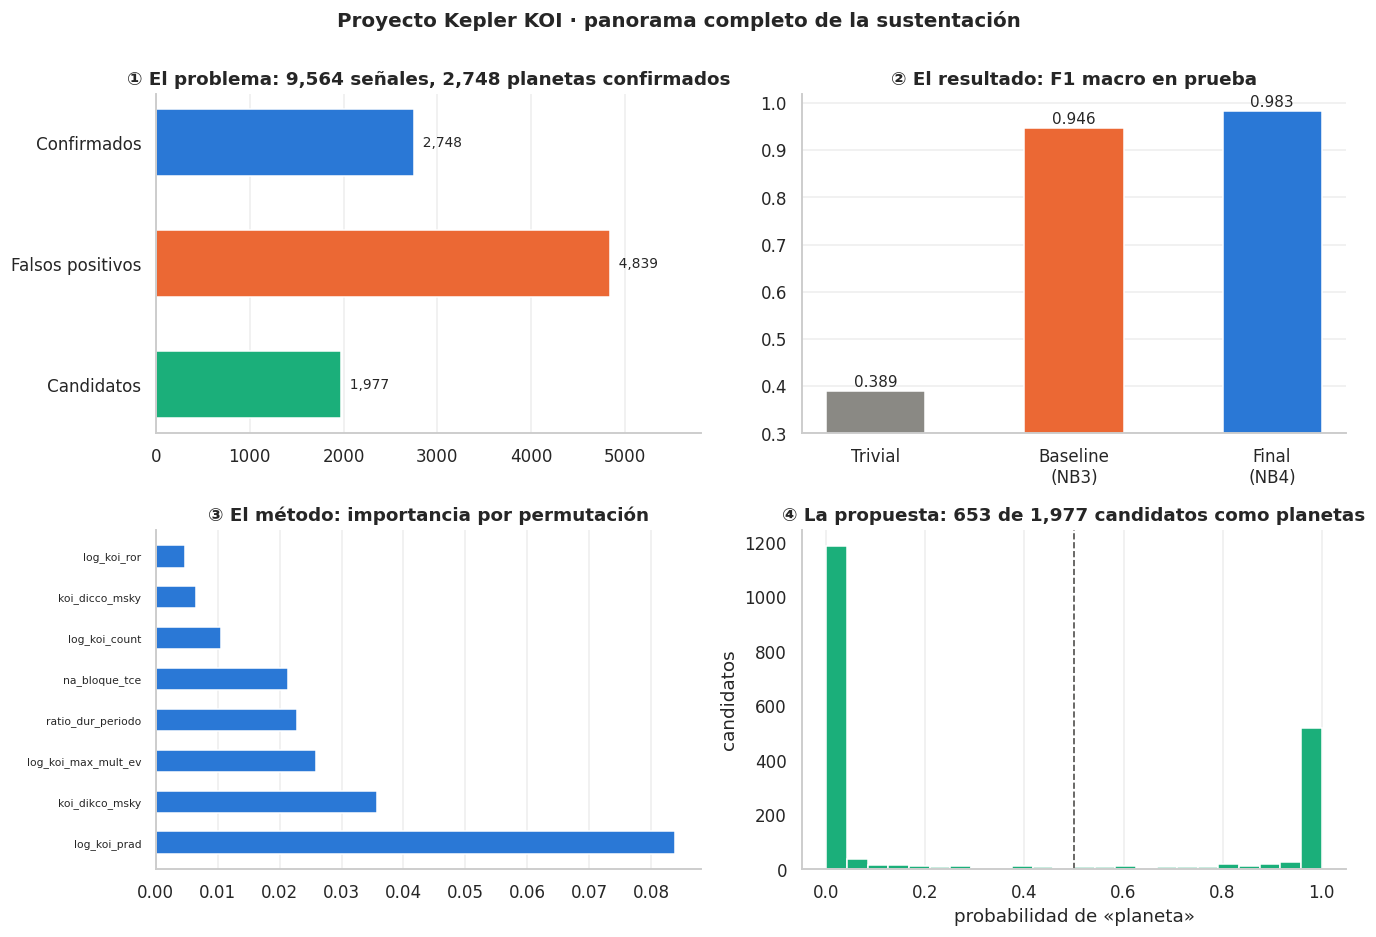

**Lectura.** Este tablero es el resumen ejecutivo del proyecto: el problema (arriba a la izquierda), el resultado medido (arriba a la derecha), el método defendible (abajo a la izquierda) y el producto final que le interesa a quien quiera priorizar observaciones (abajo a la derecha).

In [8]:
fig, axes = plt.subplots(2, 2, figsize=(12.5, 8.5))

# (a) Qué hay en los datos
ax = axes[0, 0]
conteo = raw["koi_disposition"].value_counts().reindex([CONF, FP, CAND])
NOMBRES_CLASES = {CONF: "Confirmados", FP: "Falsos positivos", CAND: "Candidatos"}
ax.barh([NOMBRES_CLASES[c] for c in conteo.index][::-1],
        conteo.values[::-1], color=[COLORES[c] for c in conteo.index[::-1]], height=0.55)
for y_, n in enumerate(conteo.values[::-1]):
    ax.text(n, y_, f"  {n:,}", va="center", fontsize=9)
ax.set_xlim(0, conteo.max() * 1.2)
ax.set_title(f"① El problema: {conteo.sum():,} señales, {conteo[CONF]:,} planetas confirmados")
ax.grid(axis="y", visible=False)

# (b) La competencia de modelos
ax = axes[0, 1]
comp = [base["prueba_trivial"]["clase_mayoritaria"]["F1 macro"],
        base["prueba"]["F1 macro"], avanz["ganador_prueba"]["F1 macro"]]
ax.bar(["Trivial", "Baseline\n(NB3)", "Final\n(NB4)"], comp,
       color=[GRIS, COLORES[FP], COLORES[CONF]], width=0.5)
for i, v in enumerate(comp):
    ax.text(i, v + 0.01, f"{v:.3f}", ha="center", fontsize=10)
ax.set_ylim(0.3, 1.02)
ax.set_title("② El resultado: F1 macro en prueba")
ax.grid(axis="x", visible=False)

# (c) Qué mira el modelo
ax = axes[1, 0]
top8 = perm.tail(8)
ax.barh(top8.index[::-1], top8.values[::-1], color=COLORES[CONF], height=0.55)
ax.set_title("③ El método: importancia por permutación")
ax.tick_params(axis="y", labelsize=7)
ax.grid(axis="y", visible=False)

# (d) Qué propone para los candidatos
ax = axes[1, 1]
ax.hist(prob_cand, bins=np.linspace(0, 1, 25), color=COLORES[CAND])
ax.axvline(0.5, color="#52514e", ls="--", lw=1.1)
ax.set(xlabel="probabilidad de «planeta»", ylabel="candidatos")
ax.set_title(f"④ La propuesta: {n_planet:,} de {len(cand):,} candidatos como planetas")
ax.grid(axis="y", visible=False)

plt.suptitle("Proyecto Kepler KOI · panorama completo de la sustentación",
             fontsize=13, fontweight="bold", y=1.0)
plt.tight_layout()
plt.show()

md("""**Lectura.** Este tablero es el resumen ejecutivo del proyecto: el problema (arriba a la izquierda), \
el resultado medido (arriba a la derecha), el método defendible (abajo a la izquierda) y el \
producto final que le interesa a quien quiera priorizar observaciones (abajo a la derecha).""")


### Conclusiones y siguientes pasos

| Mensaje para la sustentación | Evidencia en los cuadernos |
|---|---|
| El dataset permite una pregunta real con salida práctica: priorizar candidatos | NB1 (EDA), NB5 §4 |
| La limpieza decidida (fuga, MNAR, log, features físicas) es la mitad del resultado | NB2, importancia por permutación |
| La comparación justa (misma partición, prueba tocada una sola vez) hace creíbles los números | NB3 §2, NB4 §5 |
| El modelo aprende la física: vota «planeta» donde la multiplicidad lo permite | NB5 §2 |

**Cierre del proyecto (Actividades 8 y 9):** el informe técnico final toma sus cifras y figuras de
estos cinco cuadernos ejecutados; la sustentación oral se apoya en el tablero de la sección 5. El
repositorio queda reproducible de punta a punta: CSV crudo → `NB1` → `NB2` → `NB3` → `NB4` → `NB5`.

### Referencias

- Akeson, R. L., et al. (2013). The NASA Exoplanet Archive. *PASP, 125*(930), 989–999.
- Borucki, W. J., et al. (2010). Kepler planet-detection mission. *Science, 327*(5968), 977–980.
- Lissauer, J. J., et al. (2012). Almost all of Kepler's multiple-planet candidates are planets. *ApJ, 750*(2), 112.
- Thompson, S. E., et al. (2018). Planetary candidates observed by Kepler. VIII. *ApJS, 235*(2), 38.
- Tufte, E. R. (2001). *The Visual Display of Quantitative Information* (2.ª ed.). Graphics Press.